# Global versus context models

Fit clustering per fold and compare global and per-regime models; retains dependencies on part 1.

**Part 2/2 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py barrier_hit --export outputs/barrier_hit_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Test_Hit.ipynb`, original cells 198–249 (zero-based).


# Cluster Regime (เป็นไม่ใช่ Regime Dist)

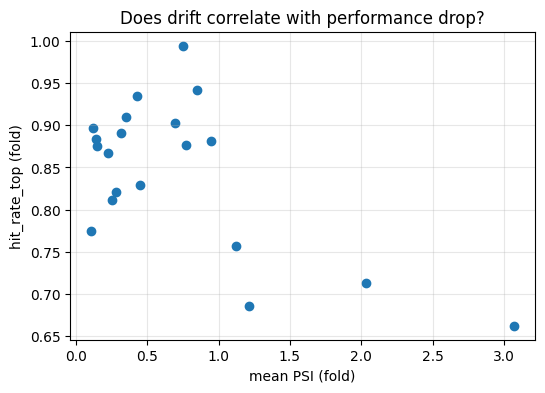

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(tmp["psi_mean"], tmp["hit_rate_top"])
plt.xlabel("mean PSI (fold)")
plt.ylabel("hit_rate_top (fold)")
plt.title("Does drift correlate with performance drop?")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import numpy as np
import polars as pl

REGIME_FEATS = [
    "rr_med_480_bps",
    "rv_sqrt_ema_480",
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480",
]

def get_regime_matrix(df: pl.DataFrame, feats=REGIME_FEATS):
    X = df.select(feats).to_numpy()
    # handle nan/inf
    X = X.astype(float)
    X[~np.isfinite(X)] = np.nan
    # simple impute with column median
    med = np.nanmedian(X, axis=0)
    inds = np.where(np.isnan(X))
    X[inds] = np.take(med, inds[1])
    return X

In [ ]:
df_bin[REGIME_FEATS]

rr_med_480_bps,rv_sqrt_ema_480,active_ms_rank_ema_480,avg_trade_q_rank_ema_480,run_mean_q_rank_ema_480
f64,f64,f64,f64,f64
6.985679,0.001204,null,null,null
6.984866,0.001201,null,null,null
6.984324,0.001197,null,null,null
6.983782,0.001194,null,null,null
6.984324,0.001192,null,null,null
…,…,…,…,…
5.017926,0.0001,0.209879,0.560373,0.411563
5.010222,0.000099,0.209048,0.561496,0.409978
5.007016,0.000099,0.20822,0.561784,0.408526


## Walk-forward clustering + labeling per fold (no leak)

In [ ]:
import tqdm

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

def label_regime_walkforward(df, folds, feats=REGIME_FEATS, n_clusters=6, seed=42):
    X = get_regime_matrix(df, feats)
    regime = np.full(len(df), -1, dtype=int)

    for i, f in enumerate(tqdm.tqdm(folds, desc="Labeling regimes")):
        tr, te = f["train_idx"], f["test_idx"]

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(X[tr])
        Xte = scaler.transform(X[te])

        km = KMeans(
            n_clusters=n_clusters,
            n_init=20,
            random_state=seed
        )
        km.fit(Xtr)

        regime[te] = km.predict(Xte)

    return regime

In [ ]:
import numpy as np
import pandas as pd

def flip_rate(states: np.ndarray) -> float:
    s = states[states >= 0]
    if len(s) <= 1:
        return np.nan
    return float(np.mean(s[1:] != s[:-1]))

def regime_size_stats(states: np.ndarray, k: int):
    s = states[states >= 0]
    cnt = np.bincount(s, minlength=k)
    frac = cnt / max(cnt.sum(), 1)
    return {
        "k": k,
        "min_frac": float(frac.min()),
        "p10_frac": float(np.quantile(frac, 0.10)),
        "max_frac": float(frac.max()),
        "entropy": float(-(frac[frac>0]*np.log(frac[frac>0])).sum()),
    }

In [ ]:
# rows = []
# for k in [3,5,7,10]:
#     rid = label_regime_walkforward(df, folds, feats=REGIME_FEATS, n_clusters=k)
#     rows.append({
#         **regime_size_stats(rid, k),
#         "flip_rate_raw": flip_rate(rid),
#     })

# pd.DataFrame(rows).sort_values("k")

In [ ]:
regime_id = label_regime_walkforward(df_bin, folds, n_clusters=6)

Labeling regimes: 100%|██████████| 20/20 [01:46<00:00,  5.33s/it]


In [ ]:
df_bin = df_bin.with_columns(pl.Series("regime_id", regime_id))

In [ ]:
import numpy as np
import polars as pl
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

REGIME_FEATS = [
    "rr_med_480_bps",
    "rv_sqrt_ema_480",
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480",
]

def _get_X(df: pl.DataFrame, feats):
    X = df.select(feats).to_numpy().astype(float)
    X[~np.isfinite(X)] = np.nan
    med = np.nanmedian(X, axis=0)
    ii = np.where(np.isnan(X))
    X[ii] = np.take(med, ii[1])
    return X

def fill_unlabeled_regimes_anchored(
    df_r: pl.DataFrame,
    *,
    tcol="t",
    regime_col="regime_id_confirmed",
    feats=REGIME_FEATS,
    K=6,
    anchor_start=None,   # เช่น "2021-01-01"
    anchor_end=None,     # เช่น "2022-01-01"
    seed=42,
):
    feats = [c for c in feats if c in df_r.columns]
    reg = df_r[regime_col].to_numpy().astype(int)

    # เลือก anchor set: (1) ช่วงเวลา หรือ (2) แถวที่ reg != -1
    if anchor_start is not None and anchor_end is not None:
        start = pl.lit(anchor_start).str.strptime(pl.Datetime)
        end   = pl.lit(anchor_end).str.strptime(pl.Datetime)

        d0 = df_r.filter(
            (pl.col(tcol) >= start) &
            (pl.col(tcol) < end)
        )
    else:
        d0 = df_r.filter(pl.col(regime_col) >= 0)

    X0 = _get_X(d0, feats)
    scaler = StandardScaler().fit(X0)
    km = KMeans(n_clusters=K, n_init=20, random_state=seed).fit(scaler.transform(X0))

    # predict ให้ทุกแถวที่ยังเป็น -1
    mask = (reg < 0)
    if mask.any():
        Xall = _get_X(df_r, feats)
        reg_pred = km.predict(scaler.transform(Xall[mask]))
        reg[mask] = reg_pred

    return df_r.with_columns(pl.Series(regime_col, reg))

In [ ]:
df_bin = fill_unlabeled_regimes_anchored(
    df_bin,
    regime_col="regime_id",
    K=6,
    # แนะนำ: กำหนดช่วง anchor เป็นปีที่ “นิ่งและเชื่อถือ” เช่น 2022
    anchor_start="2022-01-01", anchor_end="2023-01-01",
)

## EDA Regime

In [ ]:
regime_size_stats(regime_id, 6)

{'k': 6,
 'min_frac': 0.13464768163563345,
 'p10_frac': 0.13771354356821225,
 'max_frac': 0.20813138919313617,
 'entropy': 1.77675349006626}

In [ ]:
flip_rate(regime_id)

0.003978415167646026

In [ ]:
import pandas as pd

In [ ]:
import numpy as np
import polars as pl

def make_fold_id_array(n, folds):
    fold_id = np.full(n, -1, dtype=int)
    for f in folds:
        fold_id[f["test_idx"]] = f["fold"]
    return fold_id

fold_id = make_fold_id_array(len(df_bin), folds)

df_r = df_bin.with_columns([
    pl.Series("fold_id", fold_id),
    pl.Series("regime_id_raw", regime_id),
])

In [ ]:
REGIME_FEATS = [
    "rr_med_480_bps",
    "rv_sqrt_ema_480",
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480",
]
REGIME_FEATS = [c for c in REGIME_FEATS if c in df_r.columns]

In [ ]:
cent = (
    df_r
    .filter((pl.col("fold_id") >= 0) & (pl.col("regime_id_raw") >= 0))
    .group_by(["fold_id", "regime_id_raw"])
    .agg([pl.len().alias("n")] + [pl.col(c).median().alias(c) for c in REGIME_FEATS])
    .sort(["fold_id", "regime_id_raw"])
)
cent

fold_id,regime_id_raw,n,rr_med_480_bps,rv_sqrt_ema_480,active_ms_rank_ema_480,avg_trade_q_rank_ema_480,run_mean_q_rank_ema_480
i64,i64,u32,f64,f64,f64,f64,f64
0,0,31849,15.565938,0.001229,0.781278,0.343067,0.598503
0,1,43720,10.581736,0.000783,0.581393,0.368518,0.494594
0,2,25514,8.88494,0.000672,0.49448,0.635469,0.460835
0,4,2852,29.383064,0.002967,0.900669,0.449322,0.684651
0,5,28545,6.306289,0.000484,0.298747,0.447454,0.413658
…,…,…,…,…,…,…,…
19,0,61689,6.692146,0.000159,0.467859,0.386276,0.514782
19,1,36846,11.462619,0.000293,0.723192,0.38504,0.727486
19,2,11239,8.830288,0.000264,0.690801,0.586373,0.486068


In [ ]:
import numpy as np

try:
    from scipy.optimize import linear_sum_assignment
except Exception as e:
    linear_sum_assignment = None

def align_regimes_by_centroids(cent_pl: pl.DataFrame, feats: list[str], k: int):
    """
    returns mapping dict: (fold_id, old_regime) -> new_regime_aligned
    """
    cent = cent_pl.to_pandas()
    folds_sorted = sorted(cent["fold_id"].unique())
    ref_fold = folds_sorted[0]

    # get reference matrix [k x d]
    ref = cent[cent["fold_id"] == ref_fold].sort_values("regime_id_raw")
    refX = ref[feats].to_numpy(dtype=float)

    mapping = {}
    # identity mapping for ref
    for r in range(k):
        mapping[(ref_fold, r)] = r

    for fid in folds_sorted[1:]:
        cur = cent[cent["fold_id"] == fid].sort_values("regime_id_raw")
        curX = cur[feats].to_numpy(dtype=float)

        # some folds may miss regimes; handle by padding with large distance
        # build cost matrix kxk
        cost = np.full((k, k), 1e9, dtype=float)

        for i in range(min(k, curX.shape[0])):
            for j in range(min(k, refX.shape[0])):
                # cosine-like / euclid (use euclid on standardized-ish features)
                cost[i, j] = np.linalg.norm(curX[i] - refX[j])

        if linear_sum_assignment is None:
            # fallback: greedy (less optimal)
            used = set()
            for i in range(k):
                j = int(np.argmin(cost[i]))
                while j in used:
                    cost[i, j] = 1e9
                    j = int(np.argmin(cost[i]))
                used.add(j)
                mapping[(fid, i)] = j
        else:
            row_ind, col_ind = linear_sum_assignment(cost)
            for i, j in zip(row_ind, col_ind):
                mapping[(fid, int(i))] = int(j)

    return mapping, ref_fold

K = 6
mapping, ref_fold = align_regimes_by_centroids(cent, REGIME_FEATS, K)
ref_fold

np.int64(0)

In [ ]:
# build aligned regime for rows in test
reg_aligned = np.full(len(df_r), -1, dtype=int)

# map only test rows (fold_id>=0)
fold_id_np = df_r["fold_id"].to_numpy()
reg_raw_np = df_r["regime_id_raw"].to_numpy()

for i in range(len(df_r)):
    fid = int(fold_id_np[i])
    r0  = int(reg_raw_np[i])
    if fid >= 0 and r0 >= 0:
        reg_aligned[i] = mapping.get((fid, r0), -1)

df_r = df_r.with_columns(pl.Series("regime_id", reg_aligned))

In [ ]:
df_r["regime_id"].value_counts()

regime_id,count
i64,u32
1,635479
0,403339
2,700317
3,158260
4,529882
5,202163
-1,523509


In [ ]:
profile = (
    df_r
    .filter(pl.col("regime_id") >= 0)
    .group_by("regime_id")
    .agg([pl.len().alias("n")] + [pl.col(c).median().alias(c) for c in REGIME_FEATS])
    .sort("regime_id")
)
profile

regime_id,n,rr_med_480_bps,rv_sqrt_ema_480,active_ms_rank_ema_480,avg_trade_q_rank_ema_480,run_mean_q_rank_ema_480
i64,u32,f64,f64,f64,f64,f64
0,403339,11.804305,0.000405,0.702164,0.512239,0.701484
1,635479,9.697088,0.000374,0.554095,0.495666,0.510133
2,700317,7.44253,0.000305,0.451087,0.437166,0.537459
3,158260,11.690906,0.000662,0.694273,0.481389,0.559814
4,529882,5.59177,0.000197,0.309509,0.42127,0.366147
5,202163,7.724806,0.000434,0.446065,0.366726,0.518015


In [ ]:
import pandas as pd
import numpy as np

prof = profile.to_pandas()
Z = prof[REGIME_FEATS].to_numpy(float)
mu = Z.mean(axis=0)
sd = Z.std(axis=0) + 1e-12
Zs = (Z - mu) / sd
zprof = pd.DataFrame(Zs, columns=[f"{c}_z" for c in REGIME_FEATS])
zprof.insert(0, "regime_id", prof["regime_id"])
zprof.insert(1, "n", prof["n"])
zprof

,regime_id,n,rr_med_480_bps_z,rv_sqrt_ema_480_z,active_ms_rank_ema_480_z,avg_trade_q_rank_ema_480_z,run_mean_q_rank_ema_480_z
0,0,554857,0.490940,0.076778,0.927751,0.972318,1.309854
1,1,625108,-0.828784,-0.740300,-0.775402,0.190929,-0.046646
2,2,578540,-1.377912,-0.960294,-1.690767,-1.159105,-1.787301
3,3,192090,1.780820,2.070850,1.253664,0.022551,0.973679
4,4,301776,-0.035634,-0.483859,0.325573,1.341968,-0.085963
5,5,377069,-0.029431,0.036824,-0.040819,-1.368661,-0.363623


In [ ]:
import numpy as np
import pandas as pd

rid = df_r.filter(pl.col("regime_id")>=0).select("regime_id").to_numpy().reshape(-1)
T = np.zeros((K, K), dtype=float)
for a, b in zip(rid[:-1], rid[1:]):
    T[a, b] += 1
T = T / np.maximum(T.sum(axis=1, keepdims=True), 1)

Tdf = pd.DataFrame(T, index=[f"from_{i}" for i in range(K)], columns=[f"to_{j}" for j in range(K)])
Tdf

,to_0,to_1,to_2,to_3,to_4,to_5
from_0,0.996390,0.001372,0.000415,0.000553,0.000634,0.000636
from_1,0.001201,0.995735,0.001526,0.000248,0.000555,0.000734
from_2,0.000398,0.001637,0.996256,0.000017,0.000733,0.000959
from_3,0.001619,0.000797,0.000068,0.996314,0.000411,0.000791
from_4,0.001137,0.001176,0.001379,0.000262,0.995556,0.000490
from_5,0.000976,0.001193,0.001467,0.000416,0.000369,0.995579


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# เอาเฉพาะแถวที่ regime_id valid
mask = (df_r["regime_id"].to_numpy() >= 0)
Xreg = df_r.select(REGIME_FEATS).to_numpy()[mask]
yreg = df_r["regime_id"].to_numpy()[mask]

# split แบบ time: เอา 80% แรก train, 20% หลัง test
n = len(yreg)
cut = int(n*0.8)
Xtr, Xte = Xreg[:cut], Xreg[cut:]
ytr, yte = yreg[:cut], yreg[cut:]

clf = RandomForestClassifier(n_estimators=200, random_state=42, max_depth=6, n_jobs=-1)
clf.fit(Xtr, ytr)
pred = clf.predict(Xte)
print("acc:", accuracy_score(yte, pred))

imp = pd.Series(clf.feature_importances_, index=REGIME_FEATS).sort_values(ascending=False)
imp

acc: 0.47404390288426435


,0
active_ms_rank_ema_480,0.263001
run_mean_q_rank_ema_480,0.205739
rr_med_480_bps,0.185188
rv_sqrt_ema_480,0.184640
avg_trade_q_rank_ema_480,0.161433


In [ ]:
import numpy as np
import pandas as pd

DRIFT_FEATS = [
    "rr_med_480_bps",
    "rv_sqrt_ema_480",
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480",
]
DRIFT_FEATS = [c for c in DRIFT_FEATS if c in df_r.columns]

def psi(expected, actual, bins=10, eps=1e-8):
    expected = np.asarray(expected, float)
    actual   = np.asarray(actual, float)

    expected = expected[np.isfinite(expected)]
    actual   = actual[np.isfinite(actual)]
    if len(expected) < 1000 or len(actual) < 1000:
        return np.nan

    cuts = np.unique(np.quantile(expected, np.linspace(0,1,bins+1)))
    if len(cuts) < 3:
        return np.nan

    def hist(x):
        h, _ = np.histogram(x, bins=cuts)
        h = h / max(h.sum(), 1)
        return np.clip(h, eps, 1.0)

    e = hist(expected)
    a = hist(actual)
    return float(np.sum((a - e) * np.log(a / e)))

def regime_psi_matrix(df_r, regime_col="regime_id_confirmed", feats=DRIFT_FEATS, K=6, bins=10):
    reg = df_r[regime_col].to_numpy().astype(int)
    M = np.zeros((K, K), dtype=float)
    X = {c: df_r[c].to_numpy() for c in feats}

    for i in range(K):
        idx_i = np.where(reg == i)[0]
        for j in range(K):
            idx_j = np.where(reg == j)[0]
            vals = []
            for c in feats:
                vals.append(psi(X[c][idx_i], X[c][idx_j], bins=bins))
            M[i, j] = np.nanmean(vals)
    return pd.DataFrame(M, index=[f"ref_{i}" for i in range(K)], columns=[f"cmp_{j}" for j in range(K)])

psi_reg = regime_psi_matrix(df_r, regime_col="regime_id", K=6)
psi_reg

,cmp_0,cmp_1,cmp_2,cmp_3,cmp_4,cmp_5
ref_0,0.000000,0.543418,0.786832,0.405576,2.025315,1.064518
ref_1,0.584534,0.000000,0.203427,0.275743,0.788215,0.590737
ref_2,0.803920,0.221161,0.000000,0.476535,0.481303,0.317066
ref_3,0.729030,0.947390,0.501313,0.000000,1.576378,0.507053
ref_4,1.883327,0.797373,0.493005,1.046986,0.000000,0.495704
ref_5,1.139494,0.731705,0.368635,0.448873,0.795453,0.000000


In [ ]:
import pandas as pd
import numpy as np

def entropy(p):
    p = np.asarray(p, float)
    p = p[p > 0]
    return float(-(p*np.log(p)).sum())

# ต้องมี fold_id ใน df_r (test rows)
reg = df_r["regime_id"].to_numpy().astype(int)
fid = df_r["fold_id"].to_numpy().astype(int)

K = 6
rows = []
for f in sorted(np.unique(fid[fid>=0])):
    idx = np.where((fid==f) & (reg>=0))[0]
    cnt = np.bincount(reg[idx], minlength=K)
    frac = cnt / max(cnt.sum(), 1)
    rows.append({
        "fold": int(f),
        "n": int(cnt.sum()),
        "entropy_regmix": entropy(frac),
        **{f"frac_r{i}": float(frac[i]) for i in range(K)}
    })

regmix = pd.DataFrame(rows)
regmix.sort_values("fold")

,fold,n,entropy_regmix,frac_r0,frac_r1,frac_r2,frac_r3,frac_r4,frac_r5
0,0,132480,1.439135,0.240406,0.330012,0.192588,0.000000,0.021528,0.215466
1,1,129600,1.358223,0.000000,0.304306,0.249360,0.000000,0.157569,0.288765
2,2,131040,1.724841,0.163744,0.261103,0.149138,0.224313,0.120536,0.081166
3,3,132480,1.136598,0.024887,0.212160,0.533046,0.009768,0.219882,0.000257
4,4,132480,1.169377,0.216410,0.003095,0.537840,0.175566,0.000000,0.067089
5,5,129600,0.755508,0.140741,0.762600,0.000000,0.018372,0.078287,0.000000
6,6,131040,1.210293,0.277640,0.014141,0.514354,0.073542,0.119361,0.000962
7,7,132480,1.223010,0.000000,0.178986,0.079129,0.098905,0.582035,0.060945
8,8,132480,1.080599,0.031363,0.152680,0.127725,0.019648,0.652498,0.016085
9,9,129600,1.406925,0.185301,0.344637,0.251798,0.012523,0.205741,0.000000


In [ ]:
# fold_summary ต้องมี columns: fold, psi_mean (หรือ mean PSI), hit_rate_top
tmp = regmix.merge(fold_summary[["fold","psi_mean","hit_rate_top"]], on="fold", how="left")

import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.scatter(tmp["psi_mean"], tmp["entropy_regmix"])
plt.xlabel("mean PSI (fold)")
plt.ylabel("entropy of regime mix")
plt.title("Does distribution drift coincide with regime-mix shift?")
plt.grid(alpha=0.3)
plt.show()

NameError: name 'fold_summary' is not defined

## After Confirm Regime

In [ ]:
def confirm_after_x(states: np.ndarray, x: int = 30) -> np.ndarray:
    # accept new state only if it persists >= x bars
    confirmed = np.full_like(states, -1)
    cur = states[0]
    pending = cur
    streak = 1
    confirmed[0] = cur

    for i in range(1, len(states)):
        s = states[i]
        if s == cur:
            pending = s
            streak = 0
        else:
            if s == pending:
                streak += 1
            else:
                pending = s
                streak = 1

            if streak >= x:
                cur = pending
                streak = 0

        confirmed[i] = cur
    return confirmed

In [ ]:
regime_id = df_r["regime_id"].to_numpy()

In [ ]:
df_r = df_r.with_columns(pl.Series("regime_id_confirmed", confirm_after_x(regime_id, x=30)))

In [ ]:
df_r["regime_id_confirmed"].value_counts()

regime_id_confirmed,count
i64,u32
4,301259
0,555710
1,625454
2,577817
5,377112
3,192088
-1,527040


In [ ]:
folds

[{'fold': 0,
  'train_idx': array([     0,      1,      2, ..., 394497, 394498, 394499]),
  'test_idx': array([394560, 394561, 394562, ..., 527037, 527038, 527039]),
  'train_start': datetime.datetime(2019, 12, 30, 23, 0),
  'train_end': datetime.datetime(2020, 9, 30, 23, 0),
  'test_start': datetime.datetime(2020, 10, 1, 0, 0),
  'test_end': datetime.datetime(2021, 1, 1, 0, 0)},
 {'fold': 1,
  'train_idx': array([130980, 130981, 130982, ..., 526977, 526978, 526979]),
  'test_idx': array([527040, 527041, 527042, ..., 656637, 656638, 656639]),
  'train_start': datetime.datetime(2020, 3, 31, 23, 0),
  'train_end': datetime.datetime(2020, 12, 31, 23, 0),
  'test_start': datetime.datetime(2021, 1, 1, 0, 0),
  'test_end': datetime.datetime(2021, 4, 1, 0, 0)},
 {'fold': 2,
  'train_idx': array([262020, 262021, 262022, ..., 656577, 656578, 656579]),
  'test_idx': array([656640, 656641, 656642, ..., 787677, 787678, 787679]),
  'train_start': datetime.datetime(2020, 6, 30, 23, 0),
  'train_end'

## Train Per Regime

In [ ]:
import numpy as np

def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    train_idx = np.asarray(train_idx, dtype=np.int64)
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    return train_idx[:cut], train_idx[cut:]

In [ ]:
import pandas as pd
from sklearn.metrics import roc_auc_score, log_loss

def eval_metrics(y_true, p, q=0.95):
    y_true = np.asarray(y_true)
    p = np.asarray(p)

    out = {}
    out["n"] = int(len(y_true))
    out["pos_rate"] = float(np.mean(y_true)) if len(y_true) else np.nan

    if len(np.unique(y_true)) >= 2:
        out["auc"] = float(roc_auc_score(y_true, p))
    else:
        out["auc"] = np.nan

    out["logloss"] = float(log_loss(y_true, p, eps=1e-12)) if len(y_true) else np.nan

    # lift@top-q
    if len(y_true) > 0:
        thr = np.quantile(p, q)
        top = (p >= thr)
        out["n_top"] = int(top.sum())
        if top.sum() > 0:
            hit_top = float(np.mean(y_true[top]))
        else:
            hit_top = np.nan
        out["hit_top"] = hit_top
        out["lift_top"] = (hit_top / out["pos_rate"]) if (out["pos_rate"] > 0 and np.isfinite(hit_top)) else np.nan
    else:
        out["n_top"] = 0
        out["hit_top"] = np.nan
        out["lift_top"] = np.nan

    return out

## Train/eval per fold (Global vs Per-Regime)

In [ ]:
from catboost import CatBoostClassifier
from tqdm import tqdm

def train_cb_binary(Xtr, ytr, Xva, yva, *, seed=42, verbose=False):
    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        depth=7,
        learning_rate=0.07,
        iterations=2000,
        auto_class_weights="Balanced",
        random_seed=seed,
        verbose=200 if verbose else False,
        # แนะนำให้ลองเปิดเพื่อความนิ่ง:
        # subsample=0.8, rsm=0.8, l2_leaf_reg=10,
    )
    model.fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True, early_stopping_rounds=200)
    return model

def run_outer_fold_per_regime(
    df_r, X, y, folds,
    *,
    regime_col="regime_id_confirmed",
    K=6,
    val_frac=0.2,
    min_train_regime=15_000,   # ถ้าน้อยกว่านี้ไม่เทรน regime model
    min_val_regime=3000,
    q_top=0.95,
    verbose=False,
):
    reg = df_r[regime_col].to_numpy().astype(int)

    all_rows = []
    models_global = {}
    models_regime = {}  # (fold, r) -> model

    for f in tqdm(folds):
        fid = f["fold"]
        tr_idx = f["train_idx"]
        te_idx = f["test_idx"]

        # inner split ภายใน train window
        tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=val_frac)

        # --- Train GLOBAL model ---
        mg = train_cb_binary(X[tr2_idx], y[tr2_idx], X[va2_idx], y[va2_idx], verbose=verbose)
        models_global[fid] = mg

        # Evaluate global on whole test
        p_g = mg.predict_proba(X[te_idx])[:, 1]
        m_g = eval_metrics(y[te_idx], p_g, q=q_top)
        all_rows.append({
            "fold": fid, "model": "global", "regime": -1,
            **m_g,
            "test_start": f["test_start"], "test_end": f["test_end"],
        })

        # --- Train REGIME models ---
        for r in range(K):
            tr_r = tr2_idx[reg[tr2_idx] == r]
            va_r = va2_idx[reg[va2_idx] == r]
            te_r = te_idx[reg[te_idx] == r]

            # ถ้า test regime นี้ไม่มีข้อมูล ก็ข้าม
            if len(te_r) == 0:
                continue

            # ถ้า train/val น้อยไป ใช้ fallback global
            use_fallback = (len(tr_r) < min_train_regime) or (len(va_r) < min_val_regime)

            if not use_fallback:
                mr = train_cb_binary(X[tr_r], y[tr_r], X[va_r], y[va_r], verbose=verbose)
                models_regime[(fid, r)] = mr
                p_r = mr.predict_proba(X[te_r])[:, 1]
                m_r = eval_metrics(y[te_r], p_r, q=q_top)
                all_rows.append({
                    "fold": fid, "model": "per_regime", "regime": r,
                    **m_r,
                    "test_start": f["test_start"], "test_end": f["test_end"],
                })
            else:
                # fallback global on that regime slice
                p_fb = mg.predict_proba(X[te_r])[:, 1]
                m_fb = eval_metrics(y[te_r], p_fb, q=q_top)
                all_rows.append({
                    "fold": fid, "model": "fallback_global", "regime": r,
                    **m_fb,
                    "test_start": f["test_start"], "test_end": f["test_end"],
                })

    res = pd.DataFrame(all_rows)
    return res, models_global, models_regime

In [ ]:
df1, label_rep = add_tb30_label_with_report(df_r, H=30, out_col="y_tb30",k=1,rr_use_bps=True,rr_win=480)
print(label_rep)

# drop missing-fill rows + invalid labels
df1 = df1.filter((~pl.col("is_missing_fill")) & pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())

# Drop rows with missing fill or label NaN
df1 = df1.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("y_tb30").is_not_null())
)

In [ ]:
df_r

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,q_p99,…,active_ms_rank_ema_120_slope_120_bin3_robust,active_ms_rank_ema_120_slope_120_med,active_ms_rank_ema_120_slope_120_mad,active_ms_rank_ema_120_slope_120_tau,avg_trade_q_rank_ema_120_slope_120_bin3_robust_raw,avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp,avg_trade_q_rank_ema_120_slope_120_bin3_robust_streak,avg_trade_q_rank_ema_120_slope_120_bin3_robust_pending,avg_trade_q_rank_ema_120_slope_120_bin3_robust,avg_trade_q_rank_ema_120_slope_120_med,avg_trade_q_rank_ema_120_slope_120_mad,avg_trade_q_rank_ema_120_slope_120_tau,run_mean_q_rank_ema_120_slope_120_bin3_robust_raw,run_mean_q_rank_ema_120_slope_120_bin3_robust_grp,run_mean_q_rank_ema_120_slope_120_bin3_robust_streak,run_mean_q_rank_ema_120_slope_120_bin3_robust_pending,run_mean_q_rank_ema_120_slope_120_bin3_robust,run_mean_q_rank_ema_120_slope_120_med,run_mean_q_rank_ema_120_slope_120_mad,run_mean_q_rank_ema_120_slope_120_tau,rv_sqrt_q_rank_like_Lint,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_q_rank_ema_1440,rv_sqrt_ema_480_right,rv_sqrt_ema_1440_right,rv_sqrt_q_rank_ema_480_slope_30,rv_sqrt_q_rank_ema_480_slope_120,realized_range,realized_range_bps,rr_med_480,rr_med_480_bps,fold_id,regime_id_raw,regime_id,regime_id_confirmed
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,…,i8,f64,f64,f64,i8,i32,u32,i8,i8,f64,f64,f64,i8,i32,u32,i8,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,0.000002,0.539326,41,16,25,0.06,-0.06,89,437.966496,1.00526,7.70228,19.36258,…,0,null,null,null,0,null,1,0,0,null,null,null,0,null,1,0,0,null,null,null,null,null,null,null,null,0.001296,0.001296,null,null,0.23,17.826694,null,null,-1,-1,-1,-1
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,390.46987,0.31116,5.0,51.0,…,0,null,null,null,0,0,1,0,0,null,null,null,0,0,1,0,0,null,null,null,null,null,null,null,null,0.001294,0.001296,null,null,0.12,9.300884,null,null,-1,-1,-1,-1
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,493.747946,0.62237,19.0,19.38736,…,0,null,null,null,0,0,2,0,0,null,null,null,0,0,2,0,0,null,null,null,null,null,null,null,null,0.001292,0.001295,null,null,0.11,8.528454,null,null,-1,-1,-1,-1
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,110.443068,0.328,2.0,8.0,…,0,null,null,null,0,0,3,0,0,null,null,null,0,0,3,0,0,null,null,null,null,null,null,null,null,0.00129,0.001294,null,null,0.08,6.202512,null,null,-1,-1,-1,-1
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,0.000001,0.352941,33,13,20,0.05,-0.04,51,254.03189,0.62262,3.49697,18.84797,…,0,null,null,null,0,0,4,0,0,null,null,nu

In [ ]:
rgf = ['fold_id',	'regime_id_raw',	'regime_id',	'regime_id_confirmed']

In [ ]:
model_df = (
    df1.select(["t", "y_tb30"] + FEATURES + rgf)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3152949 n_features = 46


In [ ]:
df_bin = make_binary(model_df)

In [ ]:
df_bin

t,y_tb30,signed_quote,sq_rank_with_sign,sq_rank_with_sign_rank_ema_30,sq_rank_with_sign_rank_ema_120,sq_rank_with_sign_rank_ema_480,sq_rank_with_sign_rank_ema_480_slope_120,signed_quote_evt_frac_60m,signed_quote_evt_frac_240m,active_ms,active_ms_rank_ema_30,active_ms_rank_ema_120,active_ms_rank_ema_480,active_ms_rank_ema_120_slope_120,active_ms_evt_frac_60m,active_ms_evt_frac_240m,active_ms_rank_ema_120_slope_120_bin3_robust,avg_trade_q,avg_trade_q_rank_ema_30,avg_trade_q_rank_ema_120,avg_trade_q_rank_ema_480,avg_trade_q_rank_ema_120_slope_120,avg_trade_q_evt_frac_60m,avg_trade_q_evt_frac_240m,avg_trade_q_rank_ema_120_slope_120_bin3_robust,run_mean,run_mean_q_rank_ema_30,run_mean_q_rank_ema_120,run_mean_q_rank_ema_480,run_mean_q_rank_ema_120_slope_120,run_max,run_max_evt_frac_60m,run_mean_q_rank_ema_120_slope_120_bin3_robust,rv_sqrt,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_ema_480,rv_sqrt_q_rank_ema_480_slope_120,rv_sqrt_evt_frac_60m,realized_range,realized_range_bps,rr_med_480_bps,intensity_peak_1s,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,climate_state,fold_id,regime_id_raw,regime_id,regime_id_confirmed,y_hit
datetime[ms],i8,f64,f64,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,f64,f64,str,i64,i64,i64,i64,i8
2020-01-01 00:49:00,0,37860.539809,null,null,null,null,null,null,null,63,null,null,null,null,null,null,0,5.525166,null,null,null,null,null,null,0,3.043478,null,null,null,null,16,null,0,0.001003,null,null,null,0.001204,null,null,0.1,7.765784,6.985679,7,null,null,null,-1,-1,-1,-1,0
2020-01-01 00:50:00,1,2501.368,null,null,null,null,null,null,null,19,null,null,null,null,null,null,0,2.1411325,null,null,null,null,null,null,0,null,null,null,null,null,null,null,0,0.000527,null,null,null,0.001201,null,null,0.07,5.433939,6.984866,2,null,null,null,-1,-1,-1,-1,1
2020-01-01 00:51:00,1,-2693.09929,null,null,null,null,null,null,null,31,null,null,null,null,null,null,0,1.212245,null,null,null,null,null,null,0,1.823529,null,null,null,null,3,null,0,0.000388,null,null,null,0.001197,null,null,0.04,3.105831,6.984324,5,null,null,null,-1,-1,-1,-1,1
2020-01-01 00:52:00,1,1819.441145,null,null,null,null,null,null,null,21,null,null,null,null,null,null,0,0.764392,null,null,null,null,null,null,0,3.5,null,null,null,null,7,null,0,0.000291,null,null,null,0.001194,null,null,0.03,2.330278,6.983782,3,null,null,null,-1,-1,-1,-1,1
2020-01-01 00:53:00,1,-4300.808845,null,null,null,null,null,null,null,22,null,null,null,null,null,null,0,2.049376,null,null,null,null,null,null,0,2.888889,null,null,null,null,7,null,0,0.000733,null,null,null,0.001192,null,null,0.09,6.989206,6.984324,4,null,null,null,-1,-1,-1,-1,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:25:00,0,228448.934074,0.354517,0.092012,0.038063,0.03029,-0.000021,0.0,0.008333,147,0.119822,0.125862,0.209879,-0.001045,0.0,0.0,-1,0.3096612,0.626449,0.580345,0.560373,0.00052,0.033333,0.0375,0,6.410256,0.290782,0.30374,0.411563,-0.001701,62,0.0,-1,0.000045,0.129416,0.161207,0.283732,0.0001,-0.000827,0.0,0.58,1.948538,5.017926,64,0.0,0.004167,"""0_3_1""",-1,-1,-1,-1,0
2025-12-31 23:26:00,0,-42295.945493,-0.07568,0.081193,0.036183,0.029849,-0.000027,0.0,0.008333,56,0.112736,0.123947,0.209048,-0.00105,0.0,0.0,-1,0.428698,0.639614,0.58448,0.561496,0.000613,0.033333,0.0375,0,3.703704,0.273983,0.299222,0.409978,-0.001739,24,0.0,-1,0.000034,0.123256,0.159103,0.282694,0.000099,-0.00083,0.0,0.57,1.915316,5.010222,29,0.0,0.004167,"""0_3_1""",-1,-1,-1,-1,0
2025-12-31 23:27:00,0,-56161.035968,-0.106963,0.069054,0.033817,0.02928,-0.000031,0.0,0.008333,46,0.106108,0.122063,0.20822,-0.001033,0.0,0.0,-1,0.330174,0.639036,0.585243,0.561784,0.000647,0.016667,0.0375,0,4.5625,0.26023,0.295281,0.408526,-0.001708,20,0.0,-1,0.00003,0.116893,0.15688,0.28162,0.000099,-0.000827,0.0,0.4,1.3442

In [ ]:
X = (
    df_bin
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)   # แนะนำ float32 สำหรับ speed/memory
)

In [ ]:
y = df_bin["y_hit"].to_numpy()

In [ ]:
df_bin["regime_id_confirmed"].value_counts()

regime_id_confirmed,count
i64,u32
1,625086
2,576902
4,301095
3,191591
0,555408
-1,526034
5,376833


In [ ]:
K = 6
res, models_g, models_r = run_outer_fold_per_regime(
    df_r, X, y, folds,
    regime_col="regime_id_confirmed",
    K=K,
    val_frac=0.2,
    min_train_regime=15_000,
    min_val_regime=3_000,
    q_top=0.95,
    verbose=False
)

  0%|          | 0/20 [00:05<?, ?it/s]


KeyboardInterrupt: 